# Forbes Q aspheres: describing, optimizing and specifying aspheric surfaces

Almost every camera lens, phone lens and laser lens today contains
aspheres, and almost every patent still describes them as a conic plus
a power series,

$$
z(r) = \frac{c r^2}{1 + \sqrt{1 - (1+K) c^2 r^2}} + A_4 r^4 + A_6 r^6 + A_8 r^8 + \dots
$$

This is convenient to write down, and awkward to use. The monomials
$r^4, r^6, r^8, \dots$ look almost the same over the aperture, so a
surface with many terms has huge coefficients of alternating sign that
cancel each other to within micrometres; the coefficients must be
quoted to many digits; adding one more term changes all the others; and
none of the numbers says how far the surface departs from a sphere,
which is what decides whether it can be polished and tested.

G. W. Forbes (2007) proposed two orthogonal descriptions, now part of
ISO 10110-12 and of every lens design program:

- **Q-con**: a conic plus $u^4 \sum a_m Q^\mathrm{con}_m(u^2)$, Jacobi
  polynomials orthogonal in the **sag**, for mild aspheres;
- **Q-bfs**: the **best fit sphere** plus a departure along its normal,
  $u^2(1-u^2)\sum a_m Q^\mathrm{bfs}_m(u^2)$, polynomials orthonormal in the
  **slope** of the departure, for strong aspheres.

| section | content |
|---|---|
| 1 | why monomials are a poor basis: the Gram matrix |
| 2 | the Q-con and Q-bfs polynomials |
| 3 | the six aspheres of a real zoom lens in Q form |
| 4 | the ray tracer: Q surfaces against the patent's monomials |
| 5 | optimization: the same lens with monomial and with Q variables |
| 6 | specifying and testing: departure, slope and fringes, form errors |

The surfaces are `pyoptics.qaspheres.QbfsSurface` and `QconSurface`,
subclasses of `raytrace.Surface`; the zoom lens is the Olympus 12–49 mm of
notebook 127 (zoom lenses), the optimizer the damped least squares of
notebook 58 (lens optimization).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import qaspheres as qa, zoom, sketch, glasses
from pyoptics import raytrace as rt
from pyoptics import lens_optimization as lo

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. Why monomials are a poor basis

On the normalized aperture $0 \le u \le 1$ the functions $u^4, u^6,
\dots, u^{2N+2}$ all start flat and rise steeply at the rim. Their
**Gram matrix** $G_{jk} = \langle f_j, f_k\rangle$ (here with the area
weight $2u\,\mathrm du$) is the matrix of a least squares fit; its
condition number says how many digits a fit loses. For the monomials it
grows by a factor of about 15 per term, like the notorious Hilbert
matrix. Orthogonal polynomials have a diagonal Gram matrix.

monomials: cond = 1.33e+09 for 6 terms, 3.05e+15 for 10 terms
Q-con:     cond = 3.0 for 6 terms, 4.6 for 10 terms


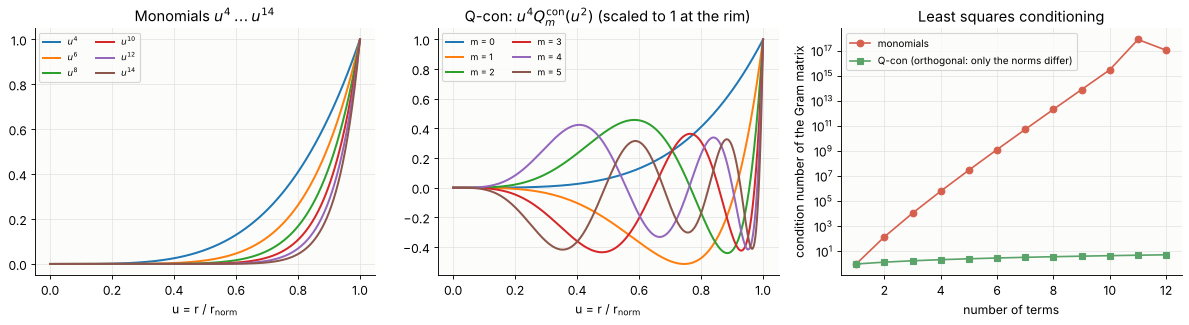

In [2]:
u = np.linspace(0, 1, 401)
N_max = 12
# Gauss-Legendre quadrature on [0, 1] in x = u^2 (the area weight 2u du = dx)
xg, wg = np.polynomial.legendre.leggauss(80)
xg, wg = (xg + 1)/2, wg/2


def gram(funcs):
    F = np.array([f(xg) for f in funcs])
    return (F*wg) @ F.T


cond_mono, cond_con = [], []
for N in range(1, N_max + 1):
    cond_mono.append(np.linalg.cond(gram([lambda x, k=k: x**(k + 2) for k in range(N)])))
    cond_con.append(np.linalg.cond(gram([lambda x, k=k: x**2*qa.qcon(k, x) for k in range(N)])))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for k in range(6):
    axes[0].plot(u, u**(2*k + 4), lw=1.8, label="$u^{{{}}}$".format(2*k + 4))
    axes[1].plot(u, u**4*qa.qcon(k, u**2)/np.abs(qa.qcon(k, 1.0)), lw=1.8, label="m = {}".format(k))
axes[0].set_title("Monomials $u^4 \\dots u^{14}$")
axes[1].set_title("Q-con: $u^4 Q_m^\\mathrm{con}(u^2)$ (scaled to 1 at the rim)")
for ax in axes[:2]:
    ax.set_xlabel("u = r / r$_\\mathrm{norm}$")
    ax.legend(fontsize=8, ncol=2)
axes[2].semilogy(range(1, N_max + 1), cond_mono, "o-", color=RED, label="monomials")
axes[2].semilogy(range(1, N_max + 1), cond_con, "s-", color=GREEN,
                 label="Q-con (orthogonal: only the norms differ)")
axes[2].set_xlabel("number of terms")
axes[2].set_ylabel("condition number of the Gram matrix")
axes[2].set_title("Least squares conditioning")
axes[2].legend(fontsize=9)
fig.tight_layout()
print("monomials: cond = {:.2e} for 6 terms, {:.2e} for 10 terms".format(cond_mono[5], cond_mono[9]))
print("Q-con:     cond = {:.1f} for 6 terms, {:.1f} for 10 terms".format(cond_con[5], cond_con[9]))

With ten monomials the fit loses 15 of the 16 digits of a double:
coefficients become meaningless, and so does any optimization variable
built from them. The Q-con polynomials are orthogonal in this inner
product, so their Gram matrix is diagonal; its condition number only
reflects the different norms of the polynomials (Forbes leaves them
unnormalized so that they are simple Jacobi polynomials).

## 2. The Q-con and Q-bfs polynomials

**Q-con** is the drop-in replacement of the power series:

$$
z = \frac{c r^2}{1 + \sqrt{1 - (1+K)c^2r^2}} + u^4\sum_{m=0}^{M} a_m\,Q_m^\mathrm{con}(u^2),
\qquad Q_m^\mathrm{con}(x) = P_m^{(0,4)}(2x - 1),
$$

with $u = r/r_\mathrm{norm}$. The factor $u^4$ keeps the vertex curvature
and conic; the polynomials are orthogonal in the sag with the weight of
the area.

**Q-bfs** starts instead from the sphere through the vertex and the
rim, the **best fit sphere** of curvature $c_\mathrm{bfs}$, and adds a
departure along its normal:

$$
z = \frac{c_\mathrm{bfs} r^2}{1 + \sqrt{1 - c_\mathrm{bfs}^2 r^2}}
  + \frac{u^2(1-u^2)}{\sqrt{1 - c_\mathrm{bfs}^2 r^2}}\sum_{m=0}^{M} a_m\,Q_m^\mathrm{bfs}(u^2).
$$

The factor $u^2(1-u^2)$ pins the departure to zero at the vertex and at
the rim, the square root turns the sag difference into a distance along
the normal of the sphere. The polynomials are orthonormal in the
**slope** of the departure,

$$
\frac{2}{\pi}\int_0^1 S_m'(u)\,S_n'(u)\,\frac{\mathrm du}{\sqrt{1-u^2}} = \delta_{mn},
\qquad S_m(u) = u^2(1-u^2)\,Q_m^\mathrm{bfs}(u^2),
$$

so that the rms slope of the departure (with the weight
$1/\sqrt{1-u^2}$, which stresses the rim) is $\sqrt{\sum a_m^2}/r_\mathrm{norm}$.
The coefficients are lengths: how much each term adds to the departure.

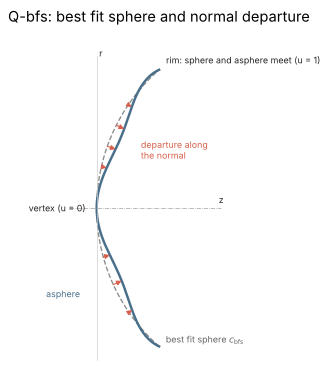

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 5.0))
sketch.qbfs_geometry(ax, title="Q-bfs: best fit sphere and normal departure")
fig.tight_layout()

Q-bfs slope Gram matrix, 10 terms: max |G - I| = 2.2e-09
Q_1 = (13 - 16x)/sqrt(19):  True
Q_2 = sqrt(2/95)(29 - 4x(25 - 19x)):  True


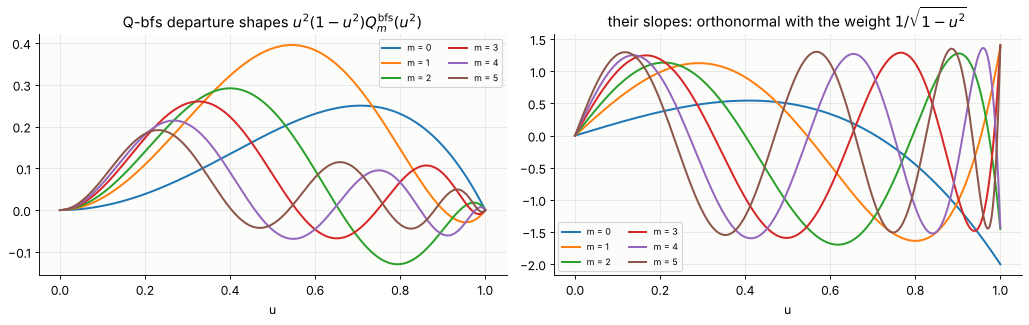

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
h = 1e-6
for m in range(6):
    S = u**2*(1 - u**2)*qa.qbfs(m, u**2)
    up, um = np.clip(u + h, 0, 1), np.clip(u - h, 0, 1)
    dS = ((up**2*(1 - up**2)*qa.qbfs(m, up**2)) - (um**2*(1 - um**2)*qa.qbfs(m, um**2)))/(up - um)
    axes[0].plot(u, S, lw=1.8, label="m = {}".format(m))
    axes[1].plot(u, dS, lw=1.8, label="m = {}".format(m))
axes[0].set_title("Q-bfs departure shapes $u^2(1-u^2)Q_m^\\mathrm{bfs}(u^2)$")
axes[1].set_title("their slopes: orthonormal with the weight $1/\\sqrt{1-u^2}$")
for ax in axes:
    ax.set_xlabel("u")
    ax.legend(fontsize=8, ncol=2)
fig.tight_layout()

# orthonormality check with Gauss-Chebyshev quadrature (exact for these polynomials)
n = 200
uc = np.cos(np.pi*(np.arange(n) + 0.5)/(2*n))      # nodes in (0, 1)


def slope(m, uu, h=1e-6):
    f = lambda v: v**2*(1 - v**2)*qa.qbfs(m, v**2)
    return (f(uu + h) - f(uu - h))/(2*h)


G = np.array([[np.mean(slope(i, uc)*slope(j, uc)) for j in range(10)] for i in range(10)])
print("Q-bfs slope Gram matrix, 10 terms: max |G - I| = {:.1e}".format(np.abs(G - np.eye(10)).max()))
print("Q_1 = (13 - 16x)/sqrt(19): ", np.allclose(qa.qbfs(1, u**2), (13 - 16*u**2)/np.sqrt(19)))
print("Q_2 = sqrt(2/95)(29 - 4x(25 - 19x)): ",
      np.allclose(qa.qbfs(2, u**2), np.sqrt(2/95)*(29 - 4*u**2*(25 - 19*u**2))))

The library builds the $Q^\mathrm{bfs}_m$ by Gram–Schmidt
orthonormalization with exact Gauss–Chebyshev quadrature and checks
against Forbes' closed forms of $Q_1$ and $Q_2$; the slope Gram matrix is
the identity to the accuracy of the finite difference slopes.

## 3. The aspheres of a real zoom lens in Q form

The Olympus 12–49 mm zoom of notebook 127 (zoom lenses) has six aspheric
surfaces, given in the patent by the vertex radius, $K = 0$ and $A_4$ to
$A_{10}$. We take each surface out to the largest ray height over the
three zoom positions (the patent gives no clear apertures) and convert
it to Q-bfs and Q-con form with `fit_qbfs()` and `fit_qcon()`.

In [5]:
Z = zoom.olympus_zoom_us7583450()
asph = [i for i, s in enumerate(Z.base.surfaces) if s.aspheric]
r_clear = {}
for k in range(3):
    s = Z.system(k)
    th = np.arctan(10.8/s.paraxial().efl)
    for fr in (0.0, 0.5, 0.7, 0.85, 1.0):
        for py in (-1.0, 1.0):
            b = s.trace_pupil(fr*th, 0.0, py)
            for i in asph:
                r_clear[i] = max(r_clear.get(i, 0.0), abs(b.points[i + 1][0, 1]))

print("surface  r_clear  R vertex   A4..A10 (patent)                               R_bfs    Q-bfs a_0..a_4 [µm]")
q_surf, c_surf = {}, {}
for i in asph:
    S = Z.base.surfaces[i]
    sag = lambda r, S=S: qa.even_asphere_sag(r, S.c, S.conic, S.aspheric)
    q_surf[i] = qa.fit_qbfs(sag, r_clear[i], 8)
    c_surf[i] = qa.fit_qcon(sag, r_clear[i], S.c, S.conic, 6)
    A = ", ".join("{:+.4e}".format(a) for a in S.aspheric)
    print("{:5s}   {:6.2f}  {:8.2f}   {:46s} {:8.2f}   {}".format(
        S.label, r_clear[i], S.R, A, q_surf[i].R,
        " ".join("{:+8.2f}".format(a*1e3) for a in q_surf[i].q[:5])))

surface  r_clear  R vertex   A4..A10 (patent)                               R_bfs    Q-bfs a_0..a_4 [µm]
r8       12.38     59.68   +1.5703e-04, -6.2535e-07, +1.8023e-09, -4.7976e-12    24.72    -541.37  -399.91    -5.20    -9.65    -0.48
r9       10.49     20.83   +1.8640e-04, -3.0654e-07, +1.6790e-09, -1.1240e-11    13.96    -503.65  -280.80   +13.49    -1.61    -0.71
r13       9.07    -24.50   +6.4830e-05, -1.4322e-07, +4.0045e-11            -30.51    -256.26   -24.35    -0.43    -0.00    +0.00
r14       8.82    -92.44   +5.2909e-05, -1.6207e-07                        -218.93    -181.01   -20.85    -0.01    +0.00    -0.00
r23      15.22     26.37   -1.5009e-05, +3.8481e-08, -1.6118e-10             30.65    +780.79  -102.74   +30.64    +1.96    -0.05
r24      15.24    -24.79   +2.6325e-05, -7.9830e-09, -7.1375e-11            -30.20    -331.10  -189.95   +12.66    +0.75    -0.00


The Q-bfs coefficients read like a spectrum: on r8 the departure from
the best fit sphere is mostly in the first two terms (−541 and −400 µm),
then −5 µm, −10 µm, −0.5 µm and practically nothing; the three weakest
aspheres (r13, r14 and r24) are almost pure $Q_0$ and $Q_1$. The
monomial coefficients $A_4 \dots A_{10}$ give no such picture: they span
eight orders of magnitude with alternating signs, and they are only
meaningful together.

Note also how different the two spheres are: r8 has a vertex radius of
59.7 mm but a best fit sphere of 24.7 mm. The surface is much more
strongly curved at the rim than at the vertex; a polisher starts from
the best fit sphere, and the departure of up to 0.28 mm (normal to it)
is what has to be made by asphere generation.

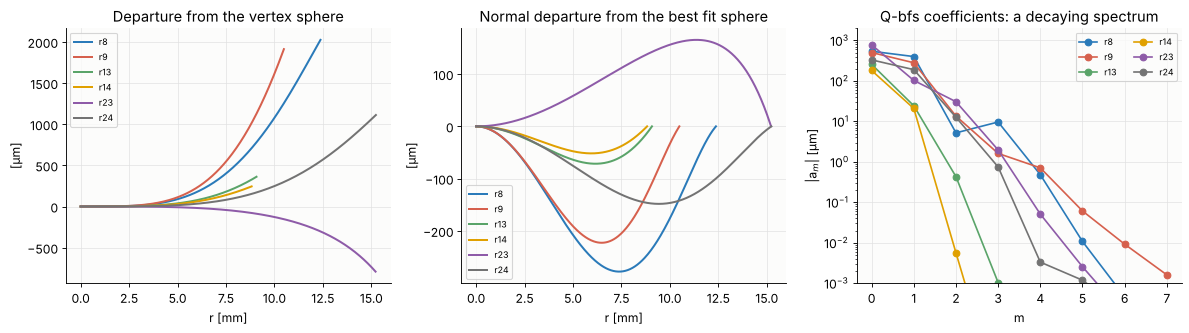

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for i, col in zip(asph, [BLUE, RED, GREEN, ORANGE, PURPLE, GREY]):
    S, Q = Z.base.surfaces[i], q_surf[i]
    r = np.linspace(0, r_clear[i], 300)
    z = qa.even_asphere_sag(r, S.c, S.conic, S.aspheric)
    dep_vertex = z - qa.even_asphere_sag(r, S.c)          # from the vertex sphere
    dep_bfs = Q.departure(r)*np.sqrt(1 - Q.c_bfs**2*r**2)  # normal departure from the bfs
    axes[0].plot(r, dep_vertex*1e3, color=col, lw=1.8, label=S.label)
    axes[1].plot(r, dep_bfs*1e3, color=col, lw=1.8, label=S.label)
    axes[2].semilogy(range(8), np.abs(Q.q)*1e3 + 1e-6, "o-", color=col, label=S.label)
axes[0].set_title("Departure from the vertex sphere")
axes[1].set_title("Normal departure from the best fit sphere")
for ax in axes[:2]:
    ax.set_xlabel("r [mm]")
    ax.set_ylabel("[µm]")
    ax.legend(fontsize=8)
axes[2].set_ylim(1e-3, 2e3)
axes[2].set_xlabel("m")
axes[2].set_ylabel("|a$_m$| [µm]")
axes[2].set_title("Q-bfs coefficients: a decaying spectrum")
axes[2].legend(fontsize=8, ncol=2)
fig.tight_layout()

**Truncation.** Because the Q-bfs terms are orthonormal, `fit_qbfs()`
simply projects the slope of the departure onto them: a fit with fewer
terms keeps the leading coefficients, and the error of dropping a term
is that term alone. A monomial fit re-balances all its coefficients
whenever a term is added or removed. As the target we take r8 in its
8-term Q-bfs form (no longer an exact polynomial in $r$), and fit it
with 3 to 6 terms of either kind:

In [7]:
S8 = Z.base.surfaces[asph[0]]
Q8 = q_surf[asph[0]]
target = lambda r: Q8.sag(np.asarray(r)**2)
rr = Q8.norm_radius
r = np.linspace(0, rr, 600)
c0 = Q8.c                                   # vertex curvature of the target
print("Q-bfs fits [µm]:")
for n in (3, 4, 5, 6):
    q = qa.fit_qbfs(target, rr, n)
    print("  {} terms: ".format(n) + " ".join("{:+9.3f}".format(a*1e3) for a in q.q)
          + "   max error {:8.4f} µm".format(np.abs(q.sag(r**2) - target(r)).max()*1e3))
print("monomial fits A_4, A_6, ... (vertex curvature fixed):")
mono_fits = {}
for n in (3, 4, 5, 6):
    M = np.stack([r**(2*k + 4) for k in range(n)], 1)
    A = np.linalg.lstsq(M, target(r) - qa.even_asphere_sag(r, c0), rcond=None)[0]
    mono_fits[n] = A
    print("  {} terms: ".format(n) + " ".join("{:+.4e}".format(a) for a in A)
          + "   max error {:8.4f} µm".format(np.abs(M @ A - target(r) + qa.even_asphere_sag(r, c0)).max()*1e3))

Q-bfs fits [µm]:
  3 terms:  -541.372  -399.915    -5.201   max error   2.6323 µm
  4 terms:  -541.372  -399.915    -5.201    -9.648   max error   0.1020 µm
  5 terms:  -541.372  -399.915    -5.201    -9.648    -0.481   max error   0.0020 µm
  6 terms:  -541.372  -399.915    -5.201    -9.648    -0.481    +0.011   max error   0.0001 µm
monomial fits A_4, A_6, ... (vertex curvature fixed):
  3 terms: +1.5243e-04 -4.7537e-07 +2.9146e-10   max error   3.8782 µm
  4 terms: +1.5703e-04 -6.2535e-07 +1.8023e-09 -4.7976e-12   max error   0.0000 µm
  5 terms: +1.5703e-04 -6.2535e-07 +1.8023e-09 -4.7976e-12 -3.4948e-20   max error   0.0000 µm
  6 terms: +5.6727e-07 +9.1109e-06 -2.2278e-07 +2.4352e-09 -1.2631e-11 +2.5133e-14   max error  18.6501 µm


**Digits.** How many significant digits must each coefficient have so
that the surface stays within 10 nm? Rounding the patent's four
monomial coefficients and the six Q-bfs coefficients of r8 to $d$
significant digits:

In [8]:
def round_sig(x, d):
    x = np.asarray(x, float)
    with np.errstate(divide="ignore"):
        e = np.where(x != 0, np.floor(np.log10(np.abs(x))), 0)
    return np.round(x/10**e, d - 1)*10**e


Q6 = qa.fit_qbfs(target, rr, 6)
A6 = np.array(S8.aspheric)                  # the patent's four coefficients
ref_m = qa.even_asphere_sag(r, S8.c, 0, A6)
print(" digits   monomials: max sag error   Q-bfs: max sag error")
for d in (2, 3, 4, 5, 6, 7):
    em = np.abs(qa.even_asphere_sag(r, S8.c, 0, round_sig(A6, d)) - ref_m).max()
    Qr = qa.QbfsSurface(Q6.R, 0, round_sig(Q6.q, d), Q6.norm_radius)
    eq = np.abs(Qr.sag(r**2) - Q6.sag(r**2)).max()
    print("   {}      {:12.4f} µm            {:12.4f} µm".format(d, em*1e3, eq*1e3))

 digits   monomials: max sag error   Q-bfs: max sag error
   2           51.4999 µm                  0.3437 µm
   3            0.9144 µm                  0.0796 µm
   4            1.0823 µm                  0.0051 µm
   5            0.0000 µm                  0.0023 µm
   6            0.0000 µm                  0.0002 µm
   7            0.0000 µm                  0.0000 µm


The Q coefficients stay stable when terms are added: the first three are
identical in all four fits, and each new term only adds its own
correction. The monomial coefficients jump when the fourth term is
added ($A_6$ from −4.75·10⁻⁷ to −6.25·10⁻⁷), and the six-term monomial fit
already breaks down in double precision: the least squares solver
discards the nearly dependent directions and the fit error jumps to
19 µm.

For the digits, this four-term asphere needs five significant digits
in its monomials (the patent prints five) and four in its Q coefficients
to stay within 10 nm; with two digits the monomial surface is 51 µm off,
the Q surface 0.3 µm. The gap grows with the number of terms:
phone lenses with $A_4$ to $A_{16}$ need many digits per monomial, while
the small, high order Q coefficients need only a few.

## 4. The ray tracer: Q surfaces against the patent's monomials

`QbfsSurface` and `QconSurface` trace exactly (Newton iterations on the
full sag from the base sphere or conic), use their vertex curvature for
the paraxial data and the $r^4$ term of the departure for the Seidel
sums. Replacing the six aspheres of the zoom by their 8-term Q-bfs fits
must leave the lens unchanged:

In [9]:
print("position  field   rms OPD patent [waves]   rms OPD Q-bfs [waves]   max |ΔOPD| [waves]")
for k in range(3):
    s = Z.system(k)
    sq = s.copy()
    for i in asph:
        Q = q_surf[i]
        old = sq.surfaces[i]
        sq.surfaces[i] = qa.QbfsSurface(Q.R, old.thickness, Q.q, Q.norm_radius,
                                        material=old.material, n_after=old.n_after,
                                        label=old.label)
    th = np.arctan(10.8/s.paraxial().efl)
    for fr in (0.0, 0.7):
        W1, W2 = s.opd(fr*th, N=32).W, sq.opd(fr*th, N=32).W
        d = np.nanmax(np.abs(W1 - W2))
        print("{:8s}  {:4.1f}    {:20.4f}   {:20.4f}   {:16.1e}".format(
            ["wide", "middle", "tele"][k], fr, np.sqrt(np.nanmean(W1**2)),
            np.sqrt(np.nanmean(W2**2)), d))
    if k == 2:
        print("efl {:.4f} (patent surfaces) / {:.4f} mm (Q-bfs), Seidel W040 {:.4f} / {:.4f} waves".format(
            s.paraxial().efl, sq.paraxial().efl, s.seidel().W040, sq.seidel().W040))

position  field   rms OPD patent [waves]   rms OPD Q-bfs [waves]   max |ΔOPD| [waves]
wide       0.0                  0.3730                 0.3730            4.7e-05


wide       0.7                  0.3726                 0.3726            1.2e-04
middle     0.0                  0.3495                 0.3495            4.7e-05


middle     0.7                  0.4032                 0.4033            7.7e-05
tele       0.0                  0.3740                 0.3740            4.7e-05


tele       0.7                  0.5749                 0.5748            1.5e-04
efl 49.1495 (patent surfaces) / 49.1495 mm (Q-bfs), Seidel W040 0.3344 / 0.3311 waves


The wavefronts agree to better than $10^{-4}$ waves, the residual of the
8-term fits; the focal lengths agree to the last digit and the Seidel
spherical aberration to 0.4 %, the r⁴ term of the fits.

## 5. Optimization: the same lens with monomial and with Q variables

A lens design program changes the coefficients of the aspheres as
variables. Damped least squares (notebook 58, lens optimization) solves
a linear least squares problem with the Jacobian in every step, and the
conditioning of section 1 enters directly: nearly dependent variables
make $J^\mathsf T J$ nearly singular, and the damping has to work hard to
take small steps along the valley.

The test case: a molded glass asphere (OHARA L-BAL42) that focuses a
405 nm laser beam of 4.8 mm diameter with $f$ = 4 mm, NA 0.6. Only the
first surface is aspheric, with $N$ = 4, 6 or 8 terms, either as
monomials $A_4 \dots$ (scaled as the sag at the rim, the best scaling
for them) or as Q-bfs coefficients. Both start from the same spheres,
both also vary the first radius, with a focus solve and the focal length
as an operand; the merit function is the wavefront on 16 rings.

In [10]:
GL = glasses.catalog(("ohara",))["L-BAL42"]
WL = 405e-6
R_PUPIL = 2.4


def collimator(kind, n_terms):
    if kind == "monomials":
        s1 = rt.Surface(3.0, 2.6, material=GL, aspheric=(0.0,)*n_terms)
        V = [lo.Curvature(0)] + [lo.Aspheric(0, o, R_PUPIL) for o in range(4, 4 + 2*n_terms, 2)]
    else:
        s1 = qa.QbfsSurface(3.0, 2.6, q=(0.0,)*n_terms, norm_radius=R_PUPIL, material=GL)
        V = [lo.Curvature(0)] + [qa.QCoefficient(0, m) for m in range(n_terms)]
    s = rt.System([s1, rt.Surface(-20.0, 2.0, n_after=1.0)], 0, WL, entrance_pupil_radius=R_PUPIL)
    return s, V


ops = [lo.paraxial_target("efl", 4.0, 0.001),
       lo.wavefront(fields=(0.0,), rings=np.linspace(0.1, 1, 16), spokes=1, tolerance=0.01)]
runs = {}
for n_terms in (4, 6, 8):
    for kind in ("monomials", "Q-bfs"):
        s, V = collimator(kind, n_terms)
        opt = lo.DampedLeastSquares(s, V, ops, solves=[lo.solve_paraxial_focus()])
        t0 = time.time()
        res = opt.run(max_iterations=120)
        J = opt.jacobian()[0]*opt._scale
        runs[kind, n_terms] = dict(history=[h["merit"] for h in res.history], system=opt.system,
                                   cond=np.linalg.cond(J.T @ J), time=time.time() - t0)
        print("{:9s} N = {}: {:3d} iterations, merit {:9.3g}, cond(JᵀJ) = {:8.2e}, "
              "rms wavefront {:.4f} waves ({:.1f} s)".format(
                  kind, n_terms, len(res.history), opt.merit(), runs[kind, n_terms]["cond"],
                  opt.system.rms_opd(0.0), runs[kind, n_terms]["time"]))

monomials N = 4:  25 iterations, merit   4.6e+04, cond(JᵀJ) = 1.59e+08, rms wavefront 0.3110 waves (0.3 s)
Q-bfs     N = 4:  14 iterations, merit      53.1, cond(JᵀJ) = 7.96e+05, rms wavefront 0.0142 waves (0.3 s)


monomials N = 6:  39 iterations, merit       715, cond(JᵀJ) = 2.18e+11, rms wavefront 0.1244 waves (0.5 s)


Q-bfs     N = 6:  17 iterations, merit    0.0201, cond(JᵀJ) = 2.14e+06, rms wavefront 0.0006 waves (0.4 s)


monomials N = 8:  50 iterations, merit      1.56, cond(JᵀJ) = 3.93e+14, rms wavefront 0.0386 waves (0.8 s)


Q-bfs     N = 8:  20 iterations, merit  6.87e-06, cond(JᵀJ) = 2.41e+07, rms wavefront 0.0001 waves (0.8 s)


Q-bfs design, N = 6: a = +193.14, -12.45, -0.81, +0.55, -0.13, +0.02 µm, R_bfs = 3.013 mm, vertex R = 2.593 mm
monomial design, N = 6: A = -3.9678e-03, -1.5725e-03, +8.0192e-04, -3.3275e-04, +5.8903e-05, -4.3140e-06, R = 2.597 mm


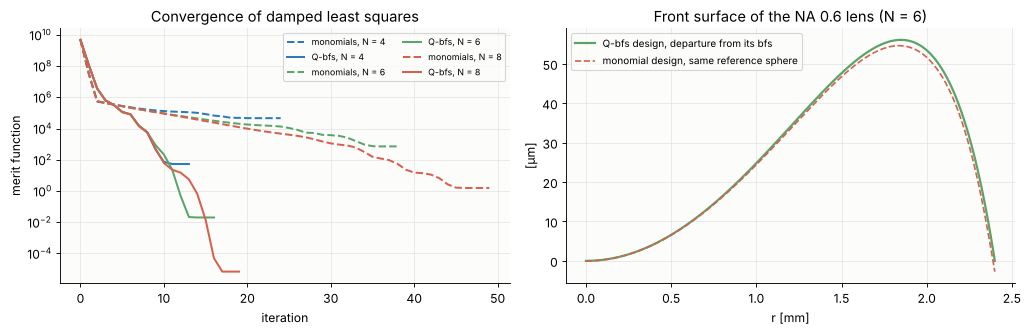

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for (kind, n_terms), r in runs.items():
    ls = "-" if kind == "Q-bfs" else "--"
    col = {4: BLUE, 6: GREEN, 8: RED}[n_terms]
    axes[0].semilogy(r["history"], ls, color=col, lw=1.8, label="{}, N = {}".format(kind, n_terms))
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("merit function")
axes[0].set_title("Convergence of damped least squares")
axes[0].legend(fontsize=8, ncol=2)
s_q = runs["Q-bfs", 6]["system"]
s_m = runs["monomials", 6]["system"]
r = np.linspace(0, R_PUPIL, 300)
Sq = s_q.surfaces[0]
axes[1].plot(r, (Sq.sag(r**2) - qa.even_asphere_sag(r, Sq.c_bfs))*1e3, color=GREEN, lw=2,
             label="Q-bfs design, departure from its bfs")
Sm = s_m.surfaces[0]
axes[1].plot(r, (Sm.sag(r**2) - qa.even_asphere_sag(r, Sq.c_bfs))*1e3, color=RED, lw=1.5, ls="--",
             label="monomial design, same reference sphere")
axes[1].set_xlabel("r [mm]")
axes[1].set_ylabel("[µm]")
axes[1].set_title("Front surface of the NA 0.6 lens (N = 6)")
axes[1].legend(fontsize=9)
fig.tight_layout()
print("Q-bfs design, N = 6: a = " + ", ".join("{:+.2f}".format(a*1e3) for a in Sq.q)
      + " µm, R_bfs = {:.3f} mm, vertex R = {:.3f} mm".format(Sq.R, 1/Sq.c))
print("monomial design, N = 6: A = " + ", ".join("{:+.4e}".format(a) for a in Sm.aspheric)
      + ", R = {:.3f} mm".format(Sm.R))

The two parameterizations span nearly the same surfaces, but the
optimizer does not see it that way. With Q-bfs variables $J^\mathsf T J$
is better conditioned by four to six orders of magnitude, damped least
squares converges in fewer iterations and reaches a far lower merit
function. With monomials it creeps: for N = 8 the condition number
reaches the limit of double precision, and the design that comes out
wiggles between the sampled rays. This is a property of the
parameterization, not of the optimizer: a better scaled set of
variables is the cheapest improvement of a lens design program.

The Q-bfs coefficients of the design are also readable: about 200 µm of
departure in the first term, then quickly smaller ones, the slope
budget of a strong but ordinary molded asphere.

## 6. Specifying and testing an asphere

What decides the cost of an asphere is not its sag but its departure
from a sphere, and above all the **slope** of that departure:

- An asphere is tested interferometrically against a spherical wave
  (or with a null corrector or a CGH). The fringe density on the
  detector is the local slope of the departure divided by the
  wavelength (twice, in reflection); beyond a few fringes per pixel the
  test fails.
- Polishing tools follow the best fit sphere; the departure is what the
  sub-aperture tools have to take off.

Forbes' rms slope $\sqrt{\sum a_m^2}/r_\mathrm{norm}$ is exactly this
number. For all aspheres of this notebook, with the maximum normal
departure from the best fit sphere and the peak fringe density of a
reflection test against a sphere at 633 nm:

In [12]:
designs = [(Z.base.surfaces[i].label + " (zoom)", q_surf[i]) for i in asph]
designs.append(("NA 0.6 collimator", s_q.surfaces[0]))
print("surface              r_norm   max departure   rms slope   max slope   fringes/mm (633 nm, 2×)")
for name, Q in designs:
    r = np.linspace(0, Q.norm_radius, 2001)
    dep = Q.departure(r)*np.sqrt(1 - Q.c_bfs**2*r**2)
    slope_dep = np.gradient(dep, r)
    print("{:20s} {:6.2f}   {:9.1f} µm   {:7.2f} mrad  {:7.2f} mrad   {:8.0f}".format(
        name, Q.norm_radius, np.abs(dep).max()*1e3, Q.rms_slope()*1e3,
        np.abs(slope_dep).max()*1e3, 2*np.abs(slope_dep).max()/633e-6))

surface              r_norm   max departure   rms slope   max slope   fringes/mm (633 nm, 2×)
r8 (zoom)             12.38       277.8 µm     54.39 mrad    82.99 mrad        262
r9 (zoom)             10.49       222.7 µm     55.00 mrad    82.93 mrad        262
r13 (zoom)             9.07        71.5 µm     28.37 mrad    52.81 mrad        167
r14 (zoom)             8.82        51.7 µm     20.65 mrad    37.75 mrad        119
r23 (zoom)            15.22       165.5 µm     51.78 mrad   114.41 mrad        361
r24 (zoom)            15.24       148.3 µm     25.07 mrad    38.07 mrad        120
NA 0.6 collimator      2.40        45.0 µm     80.64 mrad   166.96 mrad        528


The zoom lens aspheres have rms slopes of 21 to 55 mrad and peak slopes
that would give 120 to 360 fringes per millimetre in a plain spherical
test: far too many for a direct
interferometric test, so they are tested with computer generated
holograms or measured with a profilometer (or, for molded aspheres, only
the mould is measured).

**Form errors.** A specification gives a tolerance on the form, today
often as an rms slope error. In Q-bfs form a random form error is a set
of small random coefficients $\delta a_m$. With the same slope error per
term, the higher orders change the sag, and so the wavefront, less:
their slope is spread over finer ripples. A short Monte Carlo on the NA
0.6 lens (in the spirit of notebook 70, Monte Carlo tolerancing), with
random errors of 1 mrad rms slope in a single order $m$ each time:

rms wavefront for 1 mrad slope error: m=0: 0.29, m=1: 0.58, m=2: 0.54, m=3: 0.35, m=4: 0.30, m=5: 0.23, m=6: 0.21, m=7: 0.18 waves
after refocusing:                    m=0: 0.29, m=1: 0.42, m=2: 0.38, m=3: 0.32, m=4: 0.26, m=5: 0.22, m=6: 0.19, m=7: 0.16 waves


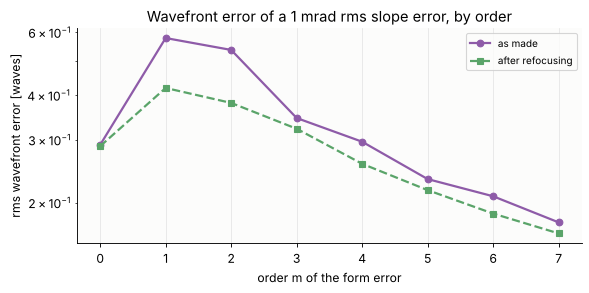

In [13]:
base = runs["Q-bfs", 6]["system"]
q0 = np.r_[base.surfaces[0].q, np.zeros(2)]
slope_rms = 1e-3                                    # 1 mrad
delta_a = slope_rms*R_PUPIL                         # one term carries all of it
W0 = base.opd(0.0, N=64).W
rms_by_m, rms_after_focus = [], []
for m in range(8):
    s = base.copy()
    q = q0.copy()
    q[m] += delta_a
    s.surfaces[0].q = tuple(q)
    dW = s.opd(0.0, N=64).W - W0                     # the wavefront is linear in a small error
    rms_by_m.append(np.sqrt(np.nanmean((dW - np.nanmean(dW))**2)))
    z = s.zernike(0.0, n_terms=9) - base.zernike(0.0, n_terms=9)
    rms_after_focus.append(np.sqrt(max(rms_by_m[-1]**2 - z[3]**2/3, 0.0)))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.semilogy(range(8), rms_by_m, "o-", color=PURPLE, lw=2, label="as made")
ax.semilogy(range(8), rms_after_focus, "s--", color=GREEN, lw=2, label="after refocusing")
ax.set_xlabel("order m of the form error")
ax.set_ylabel("rms wavefront error [waves]")
ax.set_title("Wavefront error of a 1 mrad rms slope error, by order")
ax.legend(fontsize=9)
fig.tight_layout()
print("rms wavefront for 1 mrad slope error: " + ", ".join(
    "m={}: {:.2f}".format(m, v) for m, v in enumerate(rms_by_m)) + " waves")
print("after refocusing:                    " + ", ".join(
    "m={}: {:.2f}".format(m, v) for m, v in enumerate(rms_after_focus)) + " waves")

Beyond $m = 1$ the same slope error costs fewer waves the higher its
order (0.58 waves at $m$ = 1 down to 0.18 at $m$ = 7): its slope is spread
over finer ripples with less sag. A slope specification therefore
weighs the fine ripple, which also scatters light, more heavily than a
sag (PV) specification would. Refocusing removes part of the low order
errors; the rest is spherical aberration that only a better surface
fixes.

## Summary

- Monomials $A_4 r^4 + A_6 r^6 + \dots$ are nearly dependent: the Gram
  matrix of ten terms has a condition number of about $10^{15}$.
- Forbes' Q-con (sag orthogonal, on a conic) and Q-bfs (slope
  orthonormal, on the best fit sphere) remove this. The Q-bfs
  coefficients are lengths, decay with order, are stable under
  truncation and need fewer digits.
- The six aspheres of the Olympus zoom depart by 52 to 280 µm from their
  best fit spheres, with rms slopes of 21 to 55 mrad; the Q-bfs fits
  trace to $10^{-4}$ waves of the patent's monomials.
- As optimization variables, Q coefficients condition the damped least
  squares problem by orders of magnitude better and the optimization
  converges faster and further.
- The rms slope $\sqrt{\sum a_m^2}/r_\mathrm{norm}$ is a direct measure of
  testability and a natural form tolerance.

## References

- G. W. Forbes, "Shape specification for axially symmetric optical
  surfaces", Opt. Express 15, 5218–5226 (2007).
- G. W. Forbes, "Robust, efficient computational methods for axially
  symmetric optical aspheres", Opt. Express 18, 19700–19712 (2010).
- G. W. Forbes, "Manufacturability estimates for optical aspheres", Opt.
  Express 19, 9923–9941 (2011).
- ISO 10110-12:2019, "Optics and photonics — Preparation of drawings for
  optical elements and systems — Part 12: Aspheric surfaces".
- M. Kawamura, "Zoom lens", US 7,583,450 B2 (Olympus Imaging Corp.,
  2009), example 1.

In [14]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 7 s
